In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
project_root = Path.cwd().parent

classes_path = project_root/"data/raw/elliptic/elliptic_txs_classes.csv"
features_path = project_root/"data/raw/elliptic/elliptic_txs_features.csv"
edges_path = project_root/"data/raw/elliptic/elliptic_txs_edgelist.csv"

In [10]:
classes_df = pd.read_csv(classes_path)
classes_df.head()

,txId,class
0,230425980,unknown
1,5530458,unknown
2,232022460,unknown
3,232438397,2
4,230460314,unknown


In [26]:
classes_df['class'].value_counts(normalize=True).mul(100).rename('Percentage of classes')

class
unknown    77.148634
2          20.620899
1           2.230467
Name: Percentage of classes, dtype: float64

In [47]:
classes_df['txId'].nunique()

203769

In [39]:
# No columns in this dataset
features_df = pd.read_csv(features_path, header=None)
features_df.head()

,0,1,2,3,4,5,6,7,8,9,...,157,158,159,160,161,162,163,164,165,166
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117


In [40]:
features_df.shape

(203769, 167)

In [44]:
features_df = features_df.rename(columns={
    0: "txId",
    1: "timestep"
})
features_df.columns

Index([    'txId', 'timestep',          2,          3,          4,          5,
                6,          7,          8,          9,
       ...
              157,        158,        159,        160,        161,        162,
              163,        164,        165,        166],
      dtype='object', length=167)

In [46]:
features_df['timestep'].value_counts()

timestep
1     7880
42    7140
5     6803
10    6727
3     6621
36    6393
7     6048
22    5894
4     5693
45    5598
35    5507
41    5342
47    5121
43    5063
9     4996
44    4975
24    4592
2     4544
13    4528
32    4525
40    4481
8     4457
6     4328
11    4296
20    4291
29    4275
23    4165
15    3639
21    3537
46    3519
19    3506
17    3385
37    3306
33    3151
16    2975
48    2954
38    2891
31    2816
39    2760
26    2523
34    2486
30    2483
49    2454
25    2314
12    2047
14    2022
18    1976
28    1653
27    1089
Name: count, dtype: int64

In [48]:
features_df['txId'].nunique()

203769

In [31]:
edges_df = pd.read_csv(edges_path)
edges_df.head()

,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206


In [49]:
edges_df.shape

(234355, 2)

In [52]:
print(features_df['txId'].isin(classes_df['txId']).all())

True


#### This means all transaction IDs in features_df are accounted for in classes_df

In [53]:
transactions_df = features_df.merge(
    classes_df,
    how= 'left',
    on= 'txId',
    validate='one_to_one',
    indicator='True'
)

print(transactions_df.shape)

(203769, 169)


In [55]:
transactions_df.columns

Index([    'txId', 'timestep',          2,          3,          4,          5,
                6,          7,          8,          9,
       ...
              159,        160,        161,        162,        163,        164,
              165,        166,    'class',     'True'],
      dtype='object', length=169)

### We get to know from the data source description that:

1. The time steps, running from 1 to 49, are evenly spaced with an interval of about two weeks. Each time step contains a single connected component of transactions that appeared on the blockchain within less than three hours between each other; there are no edges connecting the different time steps.

2. The first 94 features represent local information about the transaction – including the time step described above, number of inputs/outputs, transaction fee, output volume and aggregated figures such as average BTC received (spent) by the inputs/outputs and average number of incoming (outgoing) transactions associated with the inputs/outputs.

3. The remaining 72 features are aggregated features, obtained using transaction information one-hop backward/forward from the center node - giving the maximum, minimum, standard deviation and correlation coefficients of the neighbour transactions for the same information data

In [59]:
local_info_df = features_df.iloc[:,:95]
agg_info_df = pd.concat([
    features_df.iloc[:, [0]],
    features_df.iloc[:, 95:]
], axis = 1)

In [60]:
print("Local:", local_info_df.shape)
print("Aggregates:", agg_info_df.shape)

Local: (203769, 95)
Aggregates: (203769, 73)


In [63]:
display(local_info_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
txId,203769.0,1.711310e+08,1.104655e+08,1076.000000,8.433452e+07,1.624375e+08,2.454798e+08,4.032446e+08
timestep,203769.0,2.384396e+01,1.517217e+01,1.000000,9.000000e+00,2.300000e+01,3.800000e+01,4.900000e+01
2,203769.0,-8.926723e-18,1.000002e+00,-0.172983,-1.725317e-01,-1.692045e-01,-1.318553e-01,7.168197e+01
3,203769.0,0.000000e+00,1.000002e+00,-0.210553,-1.803266e-01,-1.328975e-01,-5.524241e-02,7.359505e+01
4,203769.0,3.570689e-17,1.000002e+00,-1.756361,-1.201369e+00,4.636092e-01,1.018602e+00,2.683580e+00
...,...,...,...,...,...,...,...,...
90,203769.0,8.926723e-18,1.000002e+00,-0.761984,-7.527133e-01,-4.923313e-01,4.522796e-01,6.887737e+00
91,203769.0,7.141378e-17,1.000002e+00,-0.694235,-6.925161e-01,-4.858117e-01,3.490209e-01,6.506444e+00
92,203769.0,-1.785345e-17,1.000002e+00,-0.721004,-7.122742e-01,-4.662149e-01,3.629866e-01,7.650415e+00
93,203769.0,-2.008513e-17,1.000002e+00,-1.084907,-1.084907e+00,2.530798e-02,1.135523e+00,1.135523e+00


In [64]:
display(agg_info_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
txId,203769.0,1.711310e+08,1.104655e+08,1076.000000,8.433452e+07,1.624375e+08,2.454798e+08,4.032446e+08
95,203769.0,1.115840e-17,1.000002e+00,-0.171099,-1.706381e-01,-1.664264e-01,-1.182005e-01,4.893996e+01
96,203769.0,-8.926723e-18,1.000002e+00,-0.203105,-2.018902e-01,-1.931952e-01,-1.239537e-01,1.271137e+02
97,203769.0,-2.678017e-17,1.000002e+00,-0.116817,-1.168167e-01,-1.168167e-01,-1.168167e-01,1.750089e+02
98,203769.0,0.000000e+00,1.000002e+00,-0.193369,-1.920867e-01,-1.830754e-01,-1.154302e-01,4.786299e+01
...,...,...,...,...,...,...,...,...
162,203769.0,-6.695042e-18,1.000002e+00,-0.125939,-8.749016e-02,-8.749016e-02,-8.749016e-02,2.518490e+02
163,203769.0,4.463361e-18,1.000002e+00,-0.131155,-1.311553e-01,-1.311553e-01,-8.467423e-02,2.387835e+02
164,203769.0,-1.785345e-17,1.000002e+00,-0.269818,-1.405971e-01,-9.752359e-02,-9.752359e-02,1.057340e+02
165,203769.0,-1.115840e-17,1.000002e+00,-1.760926,-1.206134e-01,-1.206134e-01,1.520067e-01,1.519700e+00


,transaction_count
timestep,
1,7880
2,4544
3,6621
4,5693
5,6803
6,4328
7,6048
8,4457
9,4996


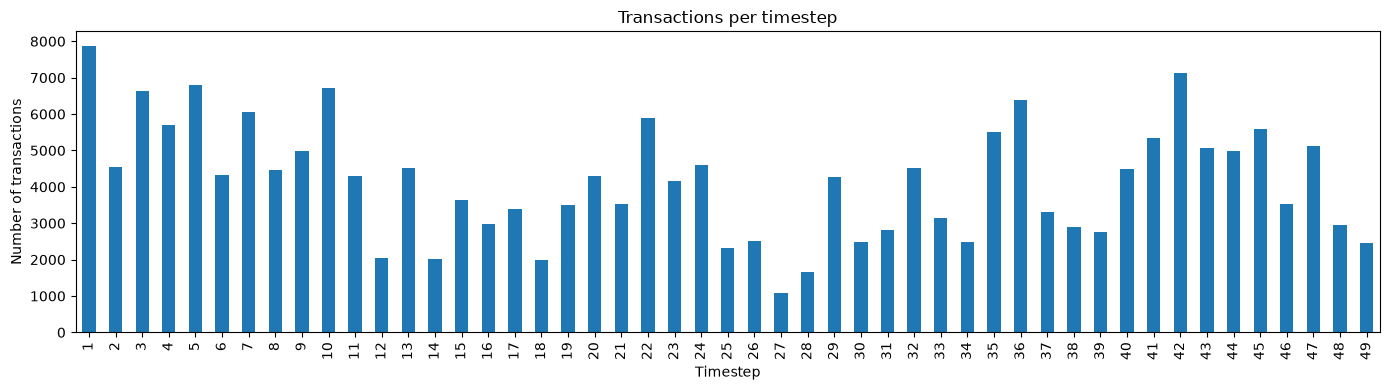

In [65]:
timestep_counts = (
    features_df.iloc[:, 1]
    .value_counts()
    .sort_index()
)

display(timestep_counts.rename("transaction_count").to_frame())

timestep_counts.plot(
    kind="bar",
    figsize=(14, 4),
    title="Transactions per timestep"
)

plt.xlabel("Timestep")
plt.ylabel("Number of transactions")
plt.tight_layout()
plt.show()

In [66]:
time_label_df = transactions_df.loc[:, ['txId', 'timestep','class']]

In [68]:
time_label_df.head()

,txId,timestep,class
0,230425980,1,unknown
1,5530458,1,unknown
2,232022460,1,unknown
3,232438397,1,2
4,230460314,1,unknown


In [74]:
label_counts_by_time = pd.crosstab(
    time_label_df['timestep'],
    time_label_df['class']
).sort_index()

display(label_counts_by_time)

class,1,2,unknown
timestep,,,
1,17,2130,5733
2,18,1099,3427
3,11,1268,5342
4,30,1410,4253
5,8,1874,4921
6,5,480,3843
7,102,1101,4845
8,67,1098,3292
9,248,530,4218


In [76]:
features_df.head()

,txId,timestep,2,3,4,5,6,7,8,9,...,157,158,159,160,161,162,163,164,165,166
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117


In [77]:
# Map transaction ID -> timestep
tx_to_timestep = features_df.set_index("txId")["timestep"]

source_steps = edges_df["txId1"].map(tx_to_timestep)
target_steps = edges_df["txId2"].map(tx_to_timestep)

cross_timestep_edges = (
    source_steps != target_steps
)

print("Total edges:", len(edges_df))
print("Cross-timestep edges:", cross_timestep_edges.sum())

Total edges: 234355
Cross-timestep edges: 0


In [78]:
# Exclude txId and timestep from the numerical feature summaries.
local_features = features_df.iloc[:, 2:95]
neighbor_features = features_df.iloc[:, 95:167]

print("Local feature shape:", local_features.shape)
print("Neighbour aggregate shape:", neighbor_features.shape)

Local feature shape: (203769, 93)
Neighbour aggregate shape: (203769, 72)


In [79]:
print("Missing local values:", local_features.isna().sum().sum())
print("Missing aggregate values:", neighbor_features.isna().sum().sum())

print(
    "Constant local features:",
    (local_features.nunique(dropna=False) == 1).sum()
)

print(
    "Constant aggregate features:",
    (neighbor_features.nunique(dropna=False) == 1).sum()
)

Missing local values: 0
Missing aggregate values: 0
Constant local features: 0
Constant aggregate features: 0


In [82]:
local_stats = local_features.describe().T
neighbor_stats = neighbor_features.describe().T

with pd.option_context("display.max_rows", None):
    display(local_stats.round(3))

with pd.option_context("display.max_rows", None):
    display(neighbor_stats.round(3))

,count,mean,std,min,25%,50%,75%,max
2,203769.0,-0.0,1.0,-0.173,-0.173,-0.169,-0.132,71.682
3,203769.0,0.0,1.0,-0.211,-0.180,-0.133,-0.055,73.595
4,203769.0,0.0,1.0,-1.756,-1.201,0.464,1.019,2.684
5,203769.0,0.0,1.0,-0.122,-0.122,-0.122,-0.122,49.028
6,203769.0,0.0,1.0,-0.064,-0.044,-0.044,-0.044,260.091
7,203769.0,0.0,1.0,-0.113,-0.113,-0.113,-0.113,54.565
8,203769.0,-0.0,1.0,-0.062,-0.062,-0.062,-0.062,113.441
9,203769.0,-0.0,1.0,-0.164,-0.164,-0.162,-0.136,73.355
10,203769.0,0.0,1.0,-0.169,-0.169,-0.166,-0.132,72.318
11,203769.0,-0.0,1.0,-0.050,-0.050,-0.050,-0.050,189.187


,count,mean,std,min,25%,50%,75%,max
95,203769.0,0.0,1.0,-0.171,-0.171,-0.166,-0.118,48.940
96,203769.0,-0.0,1.0,-0.203,-0.202,-0.193,-0.124,127.114
97,203769.0,-0.0,1.0,-0.117,-0.117,-0.117,-0.117,175.009
98,203769.0,0.0,1.0,-0.193,-0.192,-0.183,-0.115,47.863
99,203769.0,-0.0,1.0,-2.566,-0.015,-0.015,-0.015,2.537
100,203769.0,-0.0,1.0,-2.570,-0.019,-0.019,-0.019,2.532
101,203769.0,0.0,1.0,-9.177,-0.941,-0.038,0.931,1.641
102,203769.0,0.0,1.0,-9.343,-0.969,-0.050,0.935,1.658
103,203769.0,0.0,1.0,-0.083,-0.083,-0.083,-0.083,91.536
104,203769.0,0.0,1.0,-9.314,-0.962,-0.046,0.937,1.657


In [81]:
print(
    "Non-finite local values:",
    (~np.isfinite(local_features.to_numpy())).sum()
)

print(
    "Non-finite aggregate values:",
    (~np.isfinite(neighbor_features.to_numpy())).sum()
)

Non-finite local values: 0
Non-finite aggregate values: 0


In [85]:
local_stats = local_features.describe().T

local_summary = pd.DataFrame({
    "mean": local_stats["mean"],
    "std": local_stats["std"],
    "median": local_stats["50%"],
    "min": local_stats["min"],
    "max": local_stats["max"],
    "range": local_stats["max"] - local_stats["min"],
    "skewness": local_features.skew()
})

display(
    local_summary
    .sort_values("max", ascending=False)
    .head(15)
    .round(3)
)

,mean,std,median,min,max,range,skewness
37,0.0,1.0,-0.023,-0.023,289.204,289.227,148.301
35,-0.0,1.0,-0.025,-0.025,287.892,287.916,235.936
38,0.0,1.0,-0.026,-0.026,280.566,280.592,222.670
36,-0.0,1.0,-0.031,-0.031,269.701,269.732,200.436
15,-0.0,1.0,-0.043,-0.063,265.263,265.326,129.067
6,0.0,1.0,-0.044,-0.064,260.091,260.154,122.457
11,-0.0,1.0,-0.050,-0.050,189.187,189.237,71.876
17,0.0,1.0,-0.056,-0.057,183.257,183.315,86.930
71,0.0,1.0,-0.017,-0.017,152.189,152.206,91.431
74,0.0,1.0,-0.015,-0.015,151.035,151.050,129.565


In [86]:
neighbor_stats = neighbor_features.describe().T

neighbor_summary = pd.DataFrame({
    "mean": neighbor_stats["mean"],
    "std": neighbor_stats["std"],
    "median": neighbor_stats["50%"],
    "min": neighbor_stats["min"],
    "max": neighbor_stats["max"],
    "range": neighbor_stats["max"] - neighbor_stats["min"],
    "skewness": neighbor_features.skew()
})

display(
    neighbor_summary
    .sort_values("max", ascending=False)
    .head(15)
    .round(3)
)

,mean,std,median,min,max,range,skewness
162,-0.0,1.0,-0.087,-0.126,251.849,251.975,109.982
163,0.0,1.0,-0.131,-0.131,238.783,238.915,103.896
131,-0.0,1.0,-0.122,-0.125,224.459,224.584,110.015
97,-0.0,1.0,-0.117,-0.117,175.009,175.126,56.187
96,-0.0,1.0,-0.193,-0.203,127.114,127.317,29.372
161,0.0,1.0,0.018,-0.216,117.069,117.285,97.171
164,-0.0,1.0,-0.098,-0.270,105.734,106.004,53.914
134,-0.0,1.0,-0.191,-0.215,92.492,92.707,29.464
103,0.0,1.0,-0.083,-0.083,91.536,91.619,24.273
133,0.0,1.0,-0.176,-0.189,75.501,75.690,27.677


C:\Users\Asus\AppData\Local\Temp\ipykernel_24704\3319604576.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[row, 1].boxplot(values, vert=False)
C:\Users\Asus\AppData\Local\Temp\ipykernel_24704\3319604576.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[row, 1].boxplot(values, vert=False)


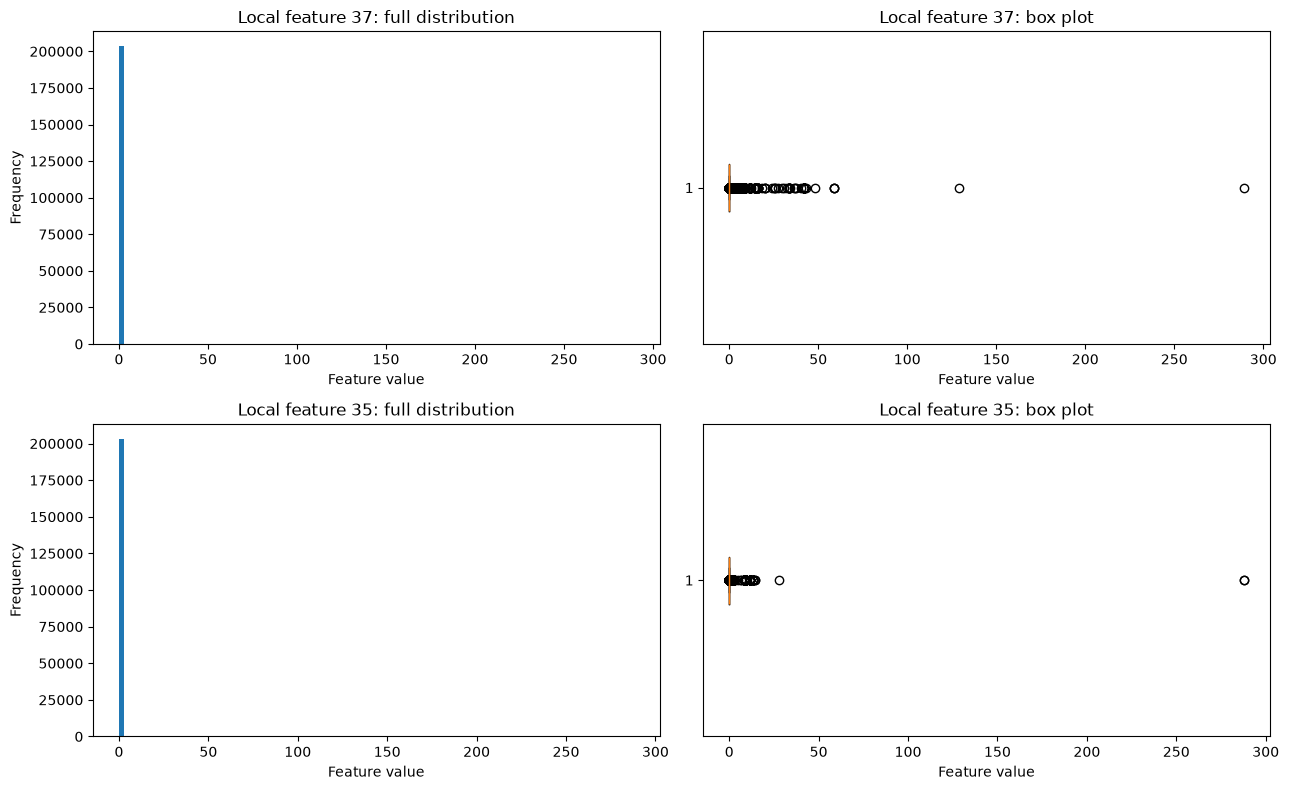

In [87]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for row, col in enumerate([37, 35]):
    values = local_features.iloc[:, col - 2]

    axes[row, 0].hist(values, bins=100)
    axes[row, 0].set_title(f"Local feature {col}: full distribution")
    axes[row, 0].set_xlabel("Feature value")
    axes[row, 0].set_ylabel("Frequency")

    axes[row, 1].boxplot(values, vert=False)
    axes[row, 1].set_title(f"Local feature {col}: box plot")
    axes[row, 1].set_xlabel("Feature value")

plt.tight_layout()
plt.show()

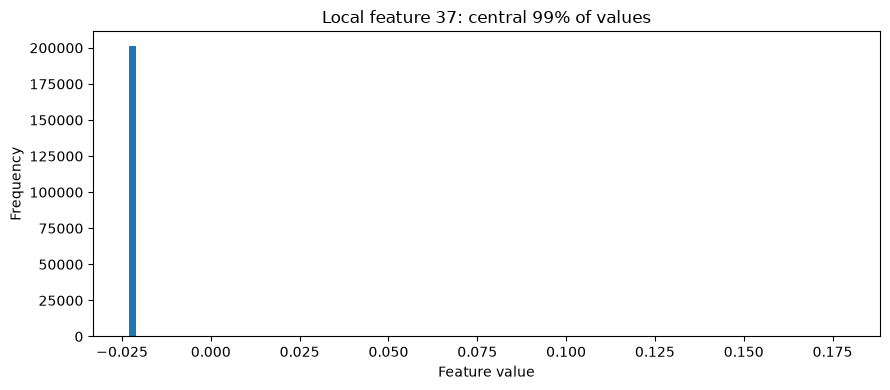

0.5th percentile: -0.0230451563960962
99.5th percentile: 0.17828896140450673
Full minimum: -0.0230451563960962
Full maximum: 289.20438805244663


In [88]:
values = local_features.iloc[:, 37 - 2]

lower, upper = values.quantile([0.005, 0.995])

plt.figure(figsize=(9, 4))
plt.hist(values, bins=100, range=(lower, upper))
plt.title("Local feature 37: central 99% of values")
plt.xlabel("Feature value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("0.5th percentile:", lower)
print("99.5th percentile:", upper)
print("Full minimum:", values.min())
print("Full maximum:", values.max())

In [89]:
values = local_features.iloc[:, 37 - 2]

print("Total transactions:", len(values))
print("Unique values:", values.nunique())
print("Minimum:", values.min())
print("Median:", values.median())
print("99th percentile:", values.quantile(0.99))
print("99.5th percentile:", values.quantile(0.995))
print("99.9th percentile:", values.quantile(0.999))
print("Maximum:", values.max())

print(
    "Transactions equal to minimum:",
    (values == values.min()).sum()
)

print(
    "Transactions above 1:",
    (values > 1).sum()
)

print(
    "Transactions above 10:",
    (values > 10).sum()
)

Total transactions: 203769
Unique values: 3908
Minimum: -0.0230451563960962
Median: -0.0230451563960962
99th percentile: -0.012674732146197343
99.5th percentile: 0.17828896140450673
99.9th percentile: 4.748400983273875
Maximum: 289.20438805244663
Transactions equal to minimum: 197319
Transactions above 1: 361
Transactions above 10: 100


In [90]:
# Join feature 37 with the labels for exploration.
feature_37_df = pd.DataFrame({
    "txId": features_df["txId"],
    "feature_37": local_features.iloc[:, 37 - 2]
}).merge(
    classes_df[["txId", "class"]],
    on="txId",
    how="left",
    validate="one_to_one"
)

# Summarise the feature separately by label.
display(
    feature_37_df.groupby("class")["feature_37"]
    .agg(
        ["count", "median", "mean", "std", "min", "max"]
    )
    .round(4)
)

,count,median,mean,std,min,max
class,,,,,,
1,4545,-0.023,-0.023,0.0005,-0.023,-0.0071
2,42019,-0.023,0.081,1.6871,-0.023,129.0891
unknown,157205,-0.023,-0.021,0.7302,-0.023,289.2044


In [91]:
feature_37_df["above_1"] = feature_37_df["feature_37"] > 1

display(
    pd.crosstab(
        feature_37_df["class"],
        feature_37_df["above_1"],
        normalize="index"
    ).mul(100).round(3)
)

above_1,False,True
class,,
1,100.000,0.000
2,99.160,0.840
unknown,99.995,0.005


In [92]:
feature_37_df = feature_37_df.merge(
    features_df[["txId", "timestep"]],
    on="txId",
    how="left",
    validate="one_to_one"
)

extreme_by_time = (
    feature_37_df.assign(above_1=lambda df: df["feature_37"] > 1)
    .groupby("timestep")
    .agg(
        transaction_count=("txId", "size"),
        extreme_count=("above_1", "sum"),
        max_feature_value=("feature_37", "max")
    )
)

extreme_by_time["extreme_percentage"] = (
    100 * extreme_by_time["extreme_count"]
    / extreme_by_time["transaction_count"]
)

display(
    extreme_by_time.sort_values(
        "extreme_count", ascending=False
    ).head(15).round(4)
)

,transaction_count,extreme_count,max_feature_value,extreme_percentage
timestep,,,,
45,5598,47,42.0723,0.8396
47,5121,28,42.0723,0.5468
41,5342,26,59.0595,0.4867
42,7140,17,42.0723,0.2381
46,3519,16,29.7429,0.4547
17,3385,16,7.0900,0.4727
43,5063,15,42.0723,0.2963
9,4996,14,8.6888,0.2802
40,4481,14,42.0723,0.3124


In [93]:
extreme_transactions = (
    feature_37_df.loc[
        feature_37_df["feature_37"] > 1,
        ["txId", "timestep", "class", "feature_37"]
    ]
    .sort_values("feature_37", ascending=False)
)

display(extreme_transactions.head(20))

print("Total transactions above 1:", len(extreme_transactions))

display(
    extreme_transactions["class"]
    .value_counts()
)

,txId,timestep,class,feature_37
115127,246026154,28,unknown,289.204388
126001,386157617,31,2,129.089084
162723,12691078,41,2,59.059530
161823,11102652,41,2,59.059530
162746,12694404,41,2,59.059530
164067,9550052,41,2,48.217676
162583,12673904,41,2,43.124767
186178,81789779,45,2,42.072324
157403,7951587,40,2,42.072324
167523,34717366,42,2,42.072324


Total transactions above 1: 361


class
2          353
unknown      8
Name: count, dtype: int64

## Temporal Split Decision

In [94]:
# Aggregate label counts for the proposed evaluation blocks.

split_blocks = {
    "Tuning fit (1-24)": (1, 24),
    "Tuning validation (25-29)": (25, 29),
    "Track A fit (1-30)": (1, 30),
    "Track A validation (31-34)": (31, 34),
    "Track A test (35-49)": (35, 49),
    "Track B test (35-38)": (35, 38),
    "Track B test (39-42)": (39, 42),
    "Track B test (43-46)": (43, 46),
    "Track B test (47-49)": (47, 49),
}

label_counts = pd.crosstab(
    transactions_df["timestep"],
    transactions_df["class"]
).reindex(columns=["1", "2", "unknown"], fill_value=0)

# Handle the case where the class labels are stored as integers.
if label_counts.sum().sum() == 0:
    label_counts = pd.crosstab(
        transactions_df["timestep"],
        transactions_df["class"]
    ).reindex(columns=[1, 2, "unknown"], fill_value=0)

rows = []

for block_name, (start, end) in split_blocks.items():
    block_counts = label_counts.loc[start:end].sum()

    illicit = int(block_counts.get("1", block_counts.get(1, 0)))
    licit = int(block_counts.get("2", block_counts.get(2, 0)))
    unknown = int(block_counts.get("unknown", 0))

    rows.append({
        "block": block_name,
        "timestep_range": f"{start}-{end}",
        "total_transactions": illicit + licit + unknown,
        "illicit": illicit,
        "licit": licit,
        "unknown": unknown,
        "known_label_count": illicit + licit,
        "illicit_pct_known": (
            100 * illicit / (illicit + licit)
            if illicit + licit else float("nan")
        )
    })

split_summary = pd.DataFrame(rows).set_index("block")
display(split_summary.round(2))


,timestep_range,total_transactions,illicit,licit,unknown,known_label_count,illicit_pct_known
block,,,,,,,
Tuning fit (1-24),1-24,108950,2219,21387,85344,23606,9.40
Tuning validation (25-29),25-29,11854,652,2123,9079,2775,23.50
Track A fit (1-30),1-30,123287,2954,23951,96382,26905,10.98
Track A validation (31-34),31-34,12978,508,2481,9989,2989,17.00
Track A test (35-49),35-49,67504,1083,15587,50834,16670,6.50
Track B test (35-38),35-38,18097,366,3937,13794,4303,8.51
Track B test (39-42),39-42,19723,548,5132,14043,5680,9.65
Track B test (43-46),43-46,19155,55,4839,14261,4894,1.12
Track B test (47-49),47-49,10529,114,1679,8736,1793,6.36


In [95]:

from pathlib import Path
import yaml

project_root = Path.cwd().parent

config_path = project_root / "configs" / "splits.yaml"

with config_path.open("r", encoding="utf-8") as f:
    split_config = yaml.safe_load(f)


def expand_range(bounds):
    """Convert an inclusive [start, end] range into a set of timesteps."""
    start, end = bounds
    assert start <= end, f"Invalid range: {bounds}"
    return set(range(start, end + 1))

def check_split(name, fit, validation, test):
    fit_steps = expand_range(fit)
    val_steps = expand_range(validation)
    test_steps = expand_range(test)

    # No timestep may appear in more than one partition.
    assert fit_steps.isdisjoint(val_steps), f"{name}: fit overlaps validation"
    assert fit_steps.isdisjoint(test_steps), f"{name}: fit overlaps test"
    assert val_steps.isdisjoint(test_steps), f"{name}: validation overlaps test"

    # Enforce chronological ordering.
    assert max(fit_steps) < min(val_steps), f"{name}: fit is not before validation"
    assert max(val_steps) < min(test_steps), f"{name}: validation is not before test"

    # Every timestep from 1 to 49 should be within the dataset's stated bounds.
    assert min(fit_steps) >= 1 and max(test_steps) <= 49

    print(
        f"{name}: PASS | "
        f"fit {min(fit_steps)}-{max(fit_steps)} | "
        f"validation {min(val_steps)}-{max(val_steps)} | "
        f"test {min(test_steps)}-{max(test_steps)}"
    )

# 2. Validate the tuning split.
check_split(
    "Tuning",
    [split_config["tuning"]["fit"]["start"],
     split_config["tuning"]["fit"]["end"]],
    [split_config["tuning"]["validation"]["start"],
     split_config["tuning"]["validation"]["end"]],
    [30, 30],  # Placeholder boundary check only; tuning is not a final evaluation.
)


Tuning: PASS | fit 1-24 | validation 25-29 | test 30-30


In [96]:

# Validate tuning separately.
tuning_fit = expand_range([
    split_config["tuning"]["fit"]["start"],
    split_config["tuning"]["fit"]["end"],
])
tuning_val = expand_range([
    split_config["tuning"]["validation"]["start"],
    split_config["tuning"]["validation"]["end"],
])

assert tuning_fit.isdisjoint(tuning_val)
assert max(tuning_fit) < min(tuning_val)
assert min(tuning_fit) == 1 and max(tuning_fit) == 24
assert min(tuning_val) == 25 and max(tuning_val) == 29

print("Tuning: PASS | fit 1-24 | validation 25-29")

# Validate Track A.
track_a = split_config["track_a"]
check_split(
    "Track A",
    [track_a["fit"]["start"], track_a["fit"]["end"]],
    [track_a["validation"]["start"], track_a["validation"]["end"]],
    [track_a["test"]["start"], track_a["test"]["end"]],
)

# Validate all Track B windows.
for window in split_config["track_b"]:
    check_split(
        window["name"],
        window["fit"],
        window["validation"],
        window["test"],
    )

# Confirm the Track B test windows cover timesteps 35-49 exactly once.
track_b_test_steps = [
    step
    for window in split_config["track_b"]
    for step in expand_range(window["test"])
]

assert sorted(track_b_test_steps) == list(range(35, 50))
assert len(track_b_test_steps) == len(set(track_b_test_steps))

print("Track B test coverage: PASS | timesteps 35-49 covered exactly once")


Tuning: PASS | fit 1-24 | validation 25-29
Track A: PASS | fit 1-30 | validation 31-34 | test 35-49
cutoff_34: PASS | fit 1-30 | validation 31-34 | test 35-38
cutoff_38: PASS | fit 1-34 | validation 35-38 | test 39-42
cutoff_42: PASS | fit 1-38 | validation 39-42 | test 43-46
cutoff_46: PASS | fit 1-42 | validation 43-46 | test 47-49
Track B test coverage: PASS | timesteps 35-49 covered exactly once


In [97]:
import pandas as pd

# Keep transaction metadata separate from model inputs.
transaction_metadata = features_df[["txId", "timestep"]].copy()

# Use the existing CSV column positions established during EDA.
X_local = features_df.iloc[:, 2:95].copy()
X_neighbour = features_df.iloc[:, 95:167].copy()

# Give the features descriptive, unambiguous column names.
X_local.columns = [f"local_{i}" for i in range(X_local.shape[1])]
X_neighbour.columns = [
    f"neighbour_{i}" for i in range(X_neighbour.shape[1])
]

# All = local transaction features + supplied neighbour aggregates.
X_all = pd.concat([X_local, X_neighbour], axis=1)

# Preserve transaction IDs as the index so rows can be aligned later.
X_local.index = features_df["txId"].to_numpy()
X_all.index = features_df["txId"].to_numpy()
transaction_metadata.index = features_df["txId"].to_numpy()

# Basic structural checks.
assert X_local.shape == (203769, 93)
assert X_all.shape == (203769, 165)
assert X_local.index.is_unique
assert X_all.index.is_unique
assert X_local.index.equals(X_all.index)
assert "timestep" not in X_local.columns
assert "timestep" not in X_all.columns

print("Local shape:", X_local.shape)
print("All shape:", X_all.shape)
print("Local feature example:", X_local.columns[:5].tolist())
print("Neighbour feature example:", X_neighbour.columns[:5].tolist())
print("Timestep excluded from model inputs: PASS")


Local shape: (203769, 93)
All shape: (203769, 165)
Local feature example: ['local_0', 'local_1', 'local_2', 'local_3', 'local_4']
Neighbour feature example: ['neighbour_0', 'neighbour_1', 'neighbour_2', 'neighbour_3', 'neighbour_4']
Timestep excluded from model inputs: PASS


In [99]:
#csr_matrix

from scipy.sparse import csr_matrix

A = csr_matrix([
    [0, 2, 0],
    [0, 0, 1],
    [0, 0, 0]
])

print("Original matrix:")
print(A.toarray())

print("\nStored values:")
print(A.data)

print("\nFirst stored value:")
print(A.data[0])

# Modify only the first stored value
A.data[0] = 0

print("\nMatrix after A.data[0] = 0:")
print(A.toarray())

print("\nStored values before eliminate_zeros:")
print(A.data)

# Remove explicitly stored zeros
A.eliminate_zeros()

print("\nStored values after eliminate_zeros:")
print(A.data)

Original matrix:
[[0 2 0]
 [0 0 1]
 [0 0 0]]

Stored values:
[2 1]

First stored value:
2

Matrix after A.data[0] = 0:
[[0 0 0]
 [0 0 1]
 [0 0 0]]

Stored values before eliminate_zeros:
[0 1]

Stored values after eliminate_zeros:
[1]


In [100]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix


def build_handcrafted_features(local_features, edges, timesteps):
    """
    Build label-free, directed graph features.

    Parameters
    ----------
    local_features : DataFrame
        Local features indexed by transaction ID.
    edges : DataFrame
        Directed edges with columns txId1 (source) and txId2 (target).
    timesteps : Series
        Timestep for each transaction, indexed by transaction ID.

    Returns
    -------
    DataFrame
        Degree features and one-hop/two-hop neighbour means.
    """
    node_ids = local_features.index
    n_nodes = len(node_ids)

    if not node_ids.is_unique:
        raise ValueError("Local feature index must contain unique transaction IDs.")

    if not timesteps.index.is_unique:
        raise ValueError("Timestep index must contain unique transaction IDs.")

    if not node_ids.isin(timesteps.index).all():
        raise ValueError("Some feature nodes have no timestep.")

    # Map transaction IDs to consecutive matrix row/column positions.
    node_to_idx = pd.Series(
        np.arange(n_nodes),
        index=node_ids
    )

    src = edges["txId1"].map(node_to_idx)
    dst = edges["txId2"].map(node_to_idx)

    if src.isna().any() or dst.isna().any():
        raise ValueError("An edge references a transaction absent from local_features.")

    src = src.to_numpy(dtype=np.int64)
    dst = dst.to_numpy(dtype=np.int64)

    # Explicitly enforce the no-cross-timestep rule.
    source_steps = timesteps.reindex(edges["txId1"]).to_numpy()
    target_steps = timesteps.reindex(edges["txId2"]).to_numpy()

    if pd.isna(source_steps).any() or pd.isna(target_steps).any():
        raise ValueError("An edge endpoint has no timestep.")

    if not np.array_equal(source_steps, target_steps):
        raise ValueError("Cross-timestep edges found.")

    # A[i, j] = 1 means there is a directed edge i -> j.
    A = csr_matrix(
        (np.ones(len(src), dtype=np.int32), (src, dst)),
        shape=(n_nodes, n_nodes),
        dtype=np.int32,
    )
    A.sum_duplicates()
    A.data[:] = 1
    A.eliminate_zeros()

    # Exactly-two-edge reachability. (Graph theory concept: (A^k)ij represents no. of directed walks of length k from node i to j)
    # Convert path counts to binary values so each destination is counted once.
    A2 = (A @ A).tocsr()
    A2.data[:] = 1

    # Exclude the source node itself if a two-edge cycle reaches it.
    A2.setdiag(0)
    A2.eliminate_zeros()

    # Use float32 to reduce memory consumption.
    X = local_features.to_numpy(dtype=np.float32, copy=True)

    def neighbour_mean(adjacency):
        counts = np.asarray(adjacency.sum(axis=1)).ravel()  #(ravel flattens it)
        sums = adjacency @ X

        # Zero-neighbour rows remain zero.
        means = np.zeros_like(sums, dtype=np.float32)
        has_neighbours = counts > 0
        means[has_neighbours] = (
            sums[has_neighbours] / counts[has_neighbours, None]
        )

        return means, counts

    # One-hop means.
    incoming_1, in_degree = neighbour_mean(A.T.tocsr())
    outgoing_1, out_degree = neighbour_mean(A)

    # Two-hop means, with unique destinations.
    incoming_2, in_degree_2 = neighbour_mean(A2.T.tocsr())
    outgoing_2, out_degree_2 = neighbour_mean(A2)

    # Assemble a reproducibly named feature table.
    result = pd.DataFrame(index=node_ids)

    result["hand_in_degree"] = in_degree
    result["hand_out_degree"] = out_degree

    feature_names = local_features.columns

    for prefix, values in [
        ("hand_in1_mean", incoming_1),
        ("hand_out1_mean", outgoing_1),
        ("hand_in2_mean", incoming_2),
        ("hand_out2_mean", outgoing_2),
    ]:
        block = pd.DataFrame(
            values,
            index=node_ids,
            columns=[f"{prefix}_{name}" for name in feature_names],
        )
        result = pd.concat([result, block], axis=1)

    # Diagnostic counts are useful for testing but aren't model features.
    diagnostics = pd.DataFrame(
        {
            "in_degree_2hop_unique": in_degree_2,
            "out_degree_2hop_unique": out_degree_2,
        },
        index=node_ids,
    )

    return result, diagnostics


In [101]:
toy_X = pd.DataFrame(
    {
        "f1": [10.0, 20.0, 30.0, 40.0],
        "f2": [1.0, 2.0, 3.0, 4.0],
    },
    index=pd.Index([101, 102, 103, 104], name="txId"),
)

toy_edges = pd.DataFrame(
    {
        "txId1": [101, 102, 104],
        "txId2": [102, 103, 102],
    }
)

toy_timesteps = pd.Series(
    {101: 1, 102: 1, 103: 1, 104: 1},
    name="timestep",
)

toy_hand, toy_diagnostics = build_handcrafted_features(
    toy_X, toy_edges, toy_timesteps
)

display(toy_hand)
display(toy_diagnostics)

# Node 102 receives edges from 101 and 104.
assert toy_hand.loc[102, "hand_in_degree"] == 2
assert np.isclose(toy_hand.loc[102, "hand_in1_mean_f1"], 25.0)

# Node 102 has one outgoing edge, to node 103.
assert toy_hand.loc[102, "hand_out_degree"] == 1
assert np.isclose(toy_hand.loc[102, "hand_out1_mean_f1"], 30.0)

# Node 101 reaches node 103 in exactly two steps: 101 -> 102 -> 103.
assert np.isclose(toy_hand.loc[101, "hand_out2_mean_f1"], 30.0)

# Node 103 has no outgoing neighbours; its means should be zero.
assert toy_hand.loc[103, "hand_out_degree"] == 0
assert np.allclose(
    toy_hand.loc[103, [c for c in toy_hand.columns if c.startswith("hand_out1_mean_")]].to_numpy(dtype=float),
    0.0,
)

print("Synthetic graph feature tests: PASS")


,hand_in_degree,hand_out_degree,hand_in1_mean_f1,hand_in1_mean_f2,hand_out1_mean_f1,hand_out1_mean_f2,hand_in2_mean_f1,hand_in2_mean_f2,hand_out2_mean_f1,hand_out2_mean_f2
txId,,,,,,,,,,
101,0,1,0.0,0.0,20.0,2.0,0.0,0.0,30.0,3.0
102,2,1,25.0,2.5,30.0,3.0,0.0,0.0,0.0,0.0
103,1,0,20.0,2.0,0.0,0.0,25.0,2.5,0.0,0.0
104,0,1,0.0,0.0,20.0,2.0,0.0,0.0,30.0,3.0


,in_degree_2hop_unique,out_degree_2hop_unique
txId,,
101,0,1
102,0,0
103,2,0
104,0,1


Synthetic graph feature tests: PASS


In [102]:
# Align timesteps to the same transaction IDs used by X_local.
timesteps_by_id = transaction_metadata["timestep"]

X_hand, hand_diagnostics = build_handcrafted_features(
    local_features=X_local,
    edges=edges_df,
    timesteps=timesteps_by_id,
)

X_local_hand = pd.concat([X_local, X_hand], axis=1)

assert X_hand.index.equals(X_local.index)
assert X_local_hand.shape == (203769, 467)
assert X_local_hand.columns.is_unique
assert "timestep" not in X_local_hand.columns

print("Handcrafted feature shape:", X_hand.shape)
print("Local+Hand shape:", X_local_hand.shape)
print("Feature columns unique:", X_local_hand.columns.is_unique)


Handcrafted feature shape: (203769, 374)
Local+Hand shape: (203769, 467)
Feature columns unique: True


In [103]:
# Summary of unique two-hop neighbour counts
display(hand_diagnostics.describe().T)

# How many transactions have no two-hop neighbours?
print(
    "No incoming 2-hop neighbours:",
    (hand_diagnostics["in_degree_2hop_unique"] == 0).sum()
)

print(
    "No outgoing 2-hop neighbours:",
    (hand_diagnostics["out_degree_2hop_unique"] == 0).sum()
)

,count,mean,std,min,25%,50%,75%,max
in_degree_2hop_unique,203769.0,1.189646,5.485187,0.0,0.0,1.0,1.0,297.0
out_degree_2hop_unique,203769.0,1.189646,3.101147,0.0,0.0,1.0,1.0,477.0


No incoming 2-hop neighbours: 89651
No outgoing 2-hop neighbours: 75142


In [104]:
# 1. Check for missing and infinite values.
print("Missing values:", X_hand.isna().sum().sum())

print(
    "Infinite values:",
    np.isinf(X_hand.to_numpy()).sum()
)

# 2. Check row alignment.
print("Index alignment:", X_hand.index.equals(X_local.index))

# 3. Check feature groups.
feature_groups = {
    "Degree": [
        "hand_in_degree",
        "hand_out_degree"
    ],
    "Incoming 1-hop": [
        c for c in X_hand.columns if c.startswith("hand_in1_mean_")
    ],
    "Outgoing 1-hop": [
        c for c in X_hand.columns if c.startswith("hand_out1_mean_")
    ],
    "Incoming 2-hop": [
        c for c in X_hand.columns if c.startswith("hand_in2_mean_")
    ],
    "Outgoing 2-hop": [
        c for c in X_hand.columns if c.startswith("hand_out2_mean_")
    ],
}

for group, columns in feature_groups.items():
    print(f"{group}: {len(columns)} columns")

# 4. Check degree distributions.
display(
    X_hand[["hand_in_degree", "hand_out_degree"]]
    .describe()
)

assert X_hand.isna().sum().sum() == 0
assert np.isfinite(X_hand.to_numpy()).all()
assert X_hand.index.equals(X_local.index)
assert all(len(columns) == 93 for group, columns in feature_groups.items()
           if group != "Degree")

print("Handcrafted feature sanity checks: PASS")

Missing values: 0
Infinite values: 0
Index alignment: True
Degree: 2 columns
Incoming 1-hop: 93 columns
Outgoing 1-hop: 93 columns
Incoming 2-hop: 93 columns
Outgoing 2-hop: 93 columns


,hand_in_degree,hand_out_degree
count,203769.000000,203769.000000
mean,1.150101,1.150101
std,3.911132,1.894740
min,0.000000,0.000000
25%,0.000000,1.000000
50%,1.000000,1.000000
75%,1.000000,1.000000
max,284.000000,472.000000


Handcrafted feature sanity checks: PASS


### Label Homophily

In [105]:
import pandas as pd
import numpy as np

# Map transaction IDs to their known labels.
label_map = transactions_df.set_index("txId")["class"].astype(str).str.strip()

source_labels = edges_df["txId1"].map(label_map)
target_labels = edges_df["txId2"].map(label_map)

known_labels = {"1", "2"}

eligible_mask = (
    source_labels.isin(known_labels)
    & target_labels.isin(known_labels)
)

eligible_source = source_labels[eligible_mask]
eligible_target = target_labels[eligible_mask]

# Count directed edges by their endpoint classes.
edge_types = pd.DataFrame({
    "source_label": eligible_source,
    "target_label": eligible_target
})

edge_counts = {
    "Illicit-Illicit": (
        (edge_types["source_label"] == "1")
        & (edge_types["target_label"] == "1")
    ).sum(),

    "Licit-Licit": (
        (edge_types["source_label"] == "2")
        & (edge_types["target_label"] == "2")
    ).sum(),

    "Illicit-Licit": (
        (edge_types["source_label"] == "1")
        & (edge_types["target_label"] == "2")
    ).sum(),

    "Licit-Illicit": (
        (edge_types["source_label"] == "2")
        & (edge_types["target_label"] == "1")
    ).sum()
}

total_eligible_edges = len(edge_types)

same_class_edges = (
    edge_counts["Illicit-Illicit"]
    + edge_counts["Licit-Licit"]
)

mixed_class_edges = (
    edge_counts["Illicit-Licit"]
    + edge_counts["Licit-Illicit"]
)

homophily = same_class_edges / total_eligible_edges

print("Total directed edges:", len(edges_df))
print("Eligible labelled edges:", total_eligible_edges)
print("Edges excluded due to unknown endpoints:", len(edges_df) - total_eligible_edges)

print("\nEdge type counts and proportions:")

edge_summary = pd.DataFrame({
    "edge_count": edge_counts,
    "percentage": {
        edge_type: count / total_eligible_edges * 100
        for edge_type, count in edge_counts.items()
    }
})

display(edge_summary)

print(f"\nSame-class edges: {same_class_edges}")
print(f"Mixed-class edges: {mixed_class_edges}")
print(f"Overall label homophily: {homophily:.4f} ({homophily * 100:.2f}%)")


Total directed edges: 234355
Eligible labelled edges: 36624
Edges excluded due to unknown endpoints: 197731

Edge type counts and proportions:


,edge_count,percentage
Illicit-Illicit,998,2.724989
Licit-Licit,33930,92.644168
Illicit-Licit,915,2.498362
Licit-Illicit,781,2.132481



Same-class edges: 34928
Mixed-class edges: 1696
Overall label homophily: 0.9537 (95.37%)
